# 03 · Elevation and Distance to Water

**Project:** Spatio-Temporal Prediction of Pluvial and Coastal Flood Risk in Lagos State, Nigeria
**Notebook:** 03 of the series · **Author:** Utibe Bassey

## Purpose

Rain falls on every LGA, but **where the water ends up depends on the land**. Low ground collects water, and land close to the lagoon, rivers or sea floods first. This notebook measures those terrain features for each LGA.

## What this notebook produces

One row per LGA (20 rows) with:

| Feature | Meaning | Why it matters |
| --- | --- | --- |
| `elev_mean_m` | Average land height above sea level | Lower ground floods more easily |
| `elev_median_m`, `elev_min_m`, `elev_max_m`, `elev_std_m` | Spread of land height | Shows flat versus uneven terrain |
| `low5_share` | Share of land below 5 m | The most flood-prone ground (coastal threshold) |
| `low10_share` | Share of land below 10 m | A wider low-lying zone |
| `slope_mean_deg` | Average slope | Flat land drains slowly |
| `water_share` | Share of the LGA that is permanent water | How much lagoon, creek or sea the LGA contains |
| `dist_water_mean_km` | Average distance from land to the nearest permanent water | Closer to water means more coastal and lagoon exposure |
| `near_water_1km_share` | Share of land within 1 km of permanent water | Land directly at the water's edge |

## Data sources (all through Google Earth Engine)

| Data | Collection | Resolution |
| --- | --- | --- |
| Elevation | SRTM, `USGS/SRTMGL1_003` | 30 m |
| Permanent water | JRC Global Surface Water, `JRC/GSW1_4/GlobalSurfaceWater` | 30 m |

## Inputs and outputs

| | File |
| --- | --- |
| **Input** | `data/clean/lagos_lgas.gpkg` (from notebook 01) |
| **Output** | `data/clean/terrain_water_lga.csv` |

## 1. Setup

In [3]:
from pathlib import Path
import json

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee   # Google Earth Engine library
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [4]:
PROJECT_ID = "lagos-flood-risk"

LGA_PATH = Path("../data/clean/lagos_lgas.gpkg")
OUT_PATH = Path("../data/clean/terrain_water_lga.csv")

TERRAIN_SCALE_M = 30       # SRTM and JRC pixel size in metres
DIST_SCALE_M = 150         # grid size used for the distance calculation (coarser = faster)
WATER_OCCURRENCE_MIN = 50  # a pixel counts as permanent water if water was present in at least 50% of observations

OUT_PATH.parent.mkdir(parents=True, exist_ok=True)

## 2. Connect to Earth Engine and load the LGA map

In [5]:
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)
print("Connected to Earth Engine")

lagos = gpd.read_file(LGA_PATH)
print("LGAs loaded:", len(lagos))

# Simplify outlines slightly (about 100 m) to keep the upload small
lagos_simple = lagos.copy()
lagos_simple["geometry"] = lagos_simple.geometry.simplify(0.001, preserve_topology=True)
lagos_fc = ee.FeatureCollection(json.loads(lagos_simple.to_json())["features"])

Connected to Earth Engine
LGAs loaded: 20


## 3. Prepare the elevation and water layers

**Why we need a water mask:** SRTM reports the lagoon and the sea as roughly 0 m. If we left them in, the "average elevation" of coastal LGAs would be pulled down by water that nobody lives on. So we use the JRC Global Surface Water map to separate **land** from **permanent water**, and measure elevation on land only.

In [6]:
# Elevation in metres above sea level
srtm = ee.Image("USGS/SRTMGL1_003").select("elevation")

# JRC water occurrence: % of observations (1984-2021) in which each pixel was water
occurrence = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").unmask(0)

water = occurrence.gte(WATER_OCCURRENCE_MIN)   # 1 = permanent water, 0 = land
land = water.Not()                             # 1 = land, 0 = water

print("Layers ready")

Layers ready


## 4. Elevation, slope and water share per LGA

A helper function does the same job for every layer: it averages (or summarises) the pixels inside each LGA and returns a table with one row per LGA.

In [7]:
def zonal(image, reducer, scale, props):
    """Summarise an Earth Engine image inside each LGA and return a pandas table indexed by LGA name."""
    fc = image.reduceRegions(collection=lagos_fc, reducer=reducer, scale=scale, tileScale=4)
    fc = fc.select(["lga"] + props, None, False)          # keep only the columns we want, drop the shapes
    rows = fc.getInfo()["features"]
    return pd.DataFrame([r["properties"] for r in rows]).set_index("lga")

In [8]:
# Four layers measured on LAND pixels only, plus the water share (measured on all pixels)
terrain_bands = ee.Image.cat([
    srtm.updateMask(land).rename("elev_mean_m"),
    srtm.lt(5).updateMask(land).rename("low5_share"),          # 1 where land is below 5 m
    srtm.lt(10).updateMask(land).rename("low10_share"),        # 1 where land is below 10 m
    ee.Terrain.slope(srtm).updateMask(land).rename("slope_mean_deg"),
    water.rename("water_share"),                               # 1 where permanent water
])

terrain_props = ["elev_mean_m", "low5_share", "low10_share", "slope_mean_deg", "water_share"]

# The mean of a 0/1 layer is the share of pixels that are 1
terrain = zonal(terrain_bands, ee.Reducer.mean(), TERRAIN_SCALE_M, terrain_props)
terrain.round(3)

,elev_mean_m,low10_share,low5_share,slope_mean_deg,water_share
lga,,,,,
Agege,41.877,0.000,0.000,2.758,0.000
Ajeromi/Ifelodun,4.913,0.941,0.457,3.131,0.000
Alimosho,27.892,0.102,0.011,2.775,0.000
Amuwo Odofin,6.425,0.785,0.362,2.785,0.080
Apapa,4.831,0.940,0.460,3.156,0.207
Badagry,7.884,0.687,0.260,2.361,0.050
Epe,12.900,0.411,0.159,2.754,0.263
Eti-Osa,5.739,0.861,0.391,2.651,0.164
Ibeju-Lekki,9.647,0.529,0.103,2.846,0.004


In [9]:
# Spread of land height: median, standard deviation, lowest and highest point
spread_reducer = (
    ee.Reducer.median()
    .combine(ee.Reducer.stdDev(), sharedInputs=True)
    .combine(ee.Reducer.min(), sharedInputs=True)
    .combine(ee.Reducer.max(), sharedInputs=True)
)

spread = zonal(srtm.updateMask(land), spread_reducer, TERRAIN_SCALE_M, ["median", "stdDev", "min", "max"])
spread = spread.rename(columns={
    "median": "elev_median_m", "stdDev": "elev_std_m", "min": "elev_min_m", "max": "elev_max_m",
})
spread.round(1)

,elev_max_m,elev_median_m,elev_min_m,elev_std_m
lga,,,,
Agege,67,45.0,11,10.2
Ajeromi/Ifelodun,21,5.0,-9,2.9
Alimosho,77,27.1,-1,14.3
Amuwo Odofin,70,6.3,-38,4.3
Apapa,26,5.0,-12,3.1
Badagry,37,7.0,-6,5.1
Epe,66,11.2,-8,10.2
Eti-Osa,35,5.0,-13,3.6
Ibeju-Lekki,29,9.2,-9,4.2


## 5. Distance to the nearest permanent water

**In plain terms:** for every patch of land, how far is the nearest lagoon, river, creek or sea? We then average that over each LGA.

**How it works:** we first shrink the water map to a 150 m grid, because the distance calculation is much faster there and 150 m is precise enough for LGA averages. Then Earth Engine's distance tool measures how far each land pixel is from the nearest water pixel.

**A built-in safety check:** the distance tool is easy to point the wrong way round (distance *to* water versus distance *from* water). The cell below tests both ways and keeps the one that is physically correct: water pixels must be near 0 and land pixels must be further away.

In [10]:
UTM_31N = "EPSG:32631"   # metric coordinate system that covers Lagos (so distances come out in metres)

# Water map on a 150 m grid: a cell is water if any 30 m pixel inside it is water
water_coarse = (
    water.reduceResolution(reducer=ee.Reducer.max(), maxPixels=1024)
    .reproject(crs=UTM_31N, scale=DIST_SCALE_M)
)

def distance_image(binary):
    """Earth Engine distance transform, converted from pixels to metres."""
    d = binary.fastDistanceTransform(256, "pixels", "squared_euclidean").sqrt().multiply(DIST_SCALE_M)
    return d.rename("dist_m")

def mean_of(img, mask):
    """Average of an image over the part of Lagos selected by a mask."""
    out = img.updateMask(mask).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=lagos_fc.geometry(),
        scale=DIST_SCALE_M, maxPixels=1e9, tileScale=4,
    )
    return out.get("dist_m").getInfo()

dist_m = None
for label, candidate in {"water": water_coarse, "not water": water_coarse.Not()}.items():
    d = distance_image(candidate)
    on_water = mean_of(d, water_coarse)             # should be about 0
    on_land = mean_of(d, water_coarse.Not())        # should be several km
    print(f"Input = {label:9s} | mean on water: {on_water:8.0f} m | mean on land: {on_land:8.0f} m")
    if on_water is not None and on_land is not None and on_water < on_land:
        dist_m = d
        print(f"  -> correct direction, using input = {label}")
        break

assert dist_m is not None, ("Distance check failed in both directions. Send me the printed numbers.")

Input = water     | mean on water:        0 m | mean on land:     3754 m
  -> correct direction, using input = water


In [11]:
land_coarse = water_coarse.Not()

dist_bands = ee.Image.cat([
    dist_m.updateMask(land_coarse).rename("dist_water_m"),
    dist_m.lt(1000).updateMask(land_coarse).rename("near_water_1km_share"),   # 1 where land is within 1 km of water
])

distance = zonal(dist_bands, ee.Reducer.mean(), DIST_SCALE_M, ["dist_water_m", "near_water_1km_share"])
distance["dist_water_mean_km"] = distance["dist_water_m"] / 1000
distance = distance.drop(columns="dist_water_m")
distance.round(3)

,near_water_1km_share,dist_water_mean_km
lga,,
Agege,0.000,8.261
Ajeromi/Ifelodun,0.171,1.833
Alimosho,0.000,12.269
Amuwo Odofin,0.406,2.213
Apapa,0.672,0.879
Badagry,0.287,2.443
Epe,0.283,3.083
Eti-Osa,0.459,1.494
Ibeju-Lekki,0.200,2.945


## 6. Combine, check and save

In [12]:
features = terrain.join(spread).join(distance).reset_index()

# Tidy: consistent column order and sensible rounding
features = features[[
    "lga", "elev_mean_m", "elev_median_m", "elev_min_m", "elev_max_m", "elev_std_m",
    "low5_share", "low10_share", "slope_mean_deg",
    "water_share", "dist_water_mean_km", "near_water_1km_share",
]]
features = features.round({
    "elev_mean_m": 1, "elev_median_m": 1, "elev_min_m": 1, "elev_max_m": 1, "elev_std_m": 1,
    "low5_share": 3, "low10_share": 3, "slope_mean_deg": 2,
    "water_share": 3, "dist_water_mean_km": 2, "near_water_1km_share": 3,
})

print("Rows:", len(features), "| LGAs:", features["lga"].nunique())
print("Missing values per column:")
print(features.isna().sum()[features.isna().sum() > 0])   # prints nothing if there are none

assert len(features) == 20 and features["lga"].nunique() == 20
assert features.drop(columns="lga").notna().all().all(), "Some values are missing. See above."
for col in ["low5_share", "low10_share", "water_share", "near_water_1km_share"]:
    assert features[col].between(0, 1).all(), f"{col} should be between 0 and 1"
assert (features["dist_water_mean_km"] >= 0).all()
print("All checks passed")

Rows: 20 | LGAs: 20
Missing values per column:
Series([], dtype: int64)
All checks passed


In [13]:
features.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH.resolve())

features.sort_values("elev_mean_m")

Saved: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\terrain_water_lga.csv


,lga,elev_mean_m,elev_median_m,elev_min_m,elev_max_m,elev_std_m,low5_share,low10_share,slope_mean_deg,water_share,dist_water_mean_km,near_water_1km_share
4,Apapa,4.8,5.0,-12,26,3.1,0.460,0.940,3.16,0.207,0.88,0.672
1,Ajeromi/Ifelodun,4.9,5.0,-9,21,2.9,0.457,0.941,3.13,0.000,1.83,0.171
7,Eti-Osa,5.7,5.0,-13,35,3.6,0.391,0.861,2.65,0.164,1.49,0.459
13,Lagos Island,5.8,4.0,-25,52,5.3,0.515,0.822,2.62,0.825,0.48,0.930
3,Amuwo Odofin,6.4,6.3,-38,70,4.3,0.362,0.785,2.78,0.080,2.21,0.406
16,Ojo,7.0,6.5,-7,32,4.1,0.278,0.775,2.55,0.054,2.82,0.256
5,Badagry,7.9,7.0,-6,37,5.1,0.260,0.687,2.36,0.050,2.44,0.287
14,Mainland,9.1,8.5,-20,33,6.2,0.211,0.626,2.99,0.002,2.03,0.166
19,Surulere,9.3,8.0,-8,33,6.2,0.184,0.664,2.82,0.000,4.30,0.004
8,Ibeju-Lekki,9.6,9.2,-9,29,4.2,0.103,0.529,2.85,0.004,2.94,0.200


## 7. Sanity-check charts

**What to look for:** the coastal and lagoon-side LGAs (such as Lagos Island, Apapa, Eti-Osa, Ajeromi/Ifelodun, Amuwo Odofin, Ibeju-Lekki and Badagry) should show the **lowest ground** and the **shortest distances to water**. The northern LGAs should be higher and further from water. If the pattern is reversed, tell me before continuing.

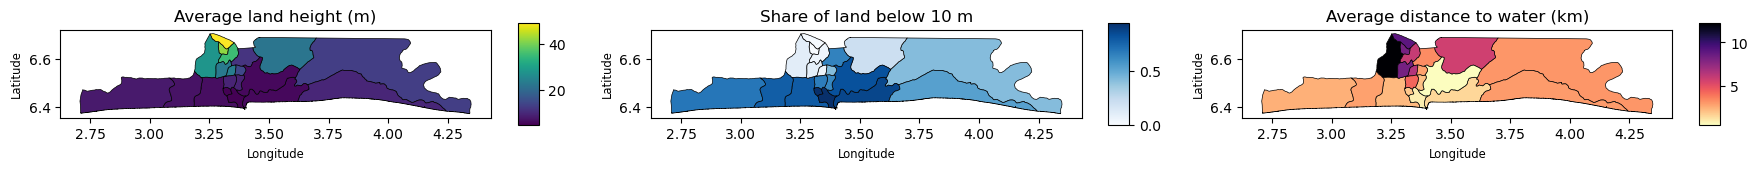

In [14]:
# Choropleth maps: colour each LGA by its value
mapped = lagos.merge(features, on="lga")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
panels = [
    ("elev_mean_m", "Average land height (m)", "viridis"),
    ("low10_share", "Share of land below 10 m", "Blues"),
    ("dist_water_mean_km", "Average distance to water (km)", "magma_r"),
]
for ax, (col, title, cmap) in zip(axes, panels):
    mapped.plot(column=col, cmap=cmap, edgecolor="black", linewidth=0.5, legend=True, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

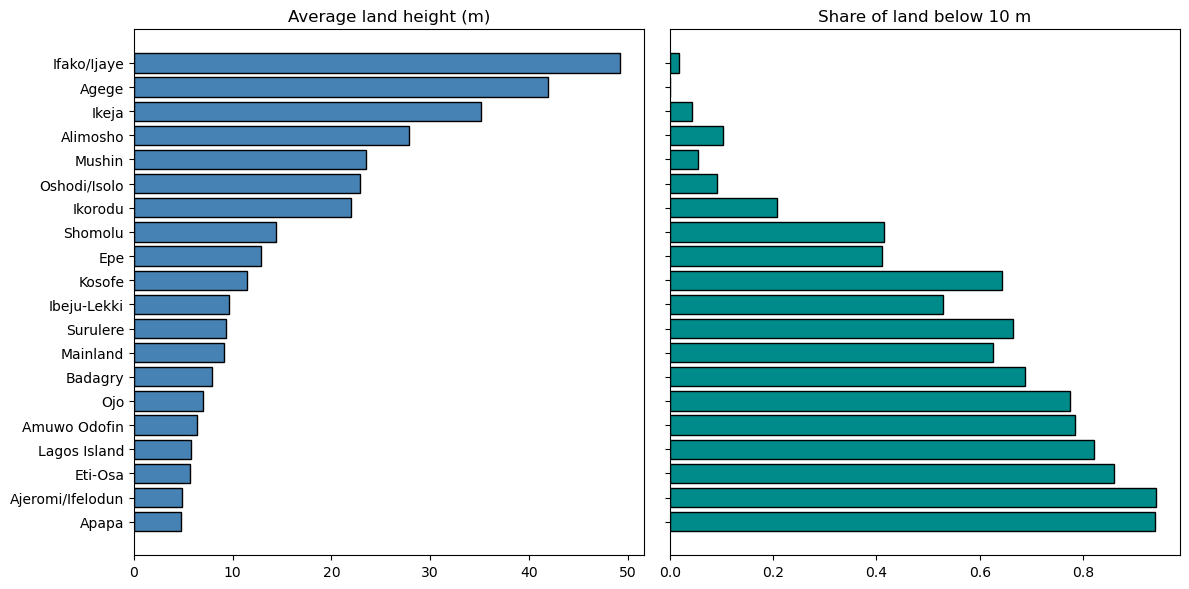

In [15]:
# Ranking by average land height, with the share of low-lying land beside it
order = features.sort_values("elev_mean_m")

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axes[0].barh(order["lga"], order["elev_mean_m"], color="steelblue", edgecolor="black")
axes[0].set_title("Average land height (m)")
axes[1].barh(order["lga"], order["low10_share"], color="darkcyan", edgecolor="black")
axes[1].set_title("Share of land below 10 m")
plt.tight_layout()
plt.show()

## Summary

- Measured **elevation, slope, low-lying land, water share and distance to water** for all 20 LGAs
- Separated land from permanent water, so lagoons and the sea do not distort the elevation figures
- Saved the table to `data/clean/terrain_water_lga.csv` (20 rows)

### Limitations to note in the report

- **SRTM is a surface model from the year 2000.** It includes treetops and buildings, and it is not a bare-ground map. Its height error is a few metres, which is large compared with Lagos's 0-10 m range. Treat the 5 m and 10 m thresholds as indicative, and the rankings between LGAs as more reliable than the exact numbers.
- **Land has changed since 2000.** Reclamation and urban growth (for example around Eti-Osa and Lekki) are not captured.
- **Permanent water only.** Wetlands, mangroves and seasonal water are not counted as water here.
- **These are LGA averages.** A large LGA can contain both very low and fairly high ground. The spread columns (`elev_std_m`, `elev_min_m`, `elev_max_m`) show this.

### Next

**`04_flood_records.ipynb`**: the hardest and most important part of the project. We collect documented Lagos flood events for 2010-2025 and decide how to label each LGA-month as "flood" or "no flood".